# Quantile Dotplot

**Family:** Uncertainty &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Uncertainty:* Show what is not known (intervals, probabilities and possible outcomes) so readers do not over-trust a single number.

## Design purpose

Turns a probability distribution into a small number of dots (here 20), each holding an equal share of probability (5%), stacked like a histogram. Readers can count dots to answer "what are my chances?" without reading a density curve. Kay et al. (2016) found that people estimate probabilities more precisely from it than from a density plot, and Fernandes et al. (2018) found that it leads to better decisions than intervals or no uncertainty display.

## When to use

- Communicate a predictive distribution to the public (arrival times, waiting times, forecasts)
- Support a threshold decision ("how likely is it before 10 minutes?")
- Show risk as frequencies, which most people find easier than percentages

## Avoid when

- You need fine detail in the tails (20–50 dots cannot show rare events)
- Comparing many distributions at once (use half-eye or gradient intervals)

## Alternatives

- Icon array (for a single probability)
- Half-eye plot
- CDF / ECDF plot (exact cumulative probabilities)

## Design tips

- Use 20, 50 or 100 dots so that one dot is a round percentage
- Highlight the dots on one side of the decision threshold and state the count
- Keep the dots round (equal aspect ratio)

## Example

A predicted bus arrival time, modelled as a log-normal distribution with a median of about 11 minutes (after the "When (ish) is my bus?" study, Kay et al., CHI 2016).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.patches import Circle
from scipy import stats

### Data

In [2]:
n_dots = 20
dist = stats.lognorm(s=0.35, scale=11)          # median ~11 minutes
q = dist.ppf((np.arange(n_dots) + 0.5) / n_dots)  # one dot per 5% of probability
threshold = 9
df = pd.DataFrame({"minutes": q.round(1), "bin": np.floor(q).astype(int)})  # bin b = [b, b+1) minutes
print(f"P(arrival ≤ {threshold} min) ≈ {dist.cdf(threshold):.0%}")
df.T

P(arrival ≤ 9 min) ≈ 28%


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
minutes,5.5,6.6,7.4,7.9,8.4,8.9,9.4,9.8,10.3,10.8,11.2,11.8,12.3,12.9,13.6,14.3,15.3,16.5,18.2,21.8
bin,5.0,6.0,7.0,7.0,8.0,8.0,9.0,9.0,10.0,10.0,11.0,11.0,12.0,12.0,13.0,14.0,15.0,16.0,18.0,21.0


### Plot

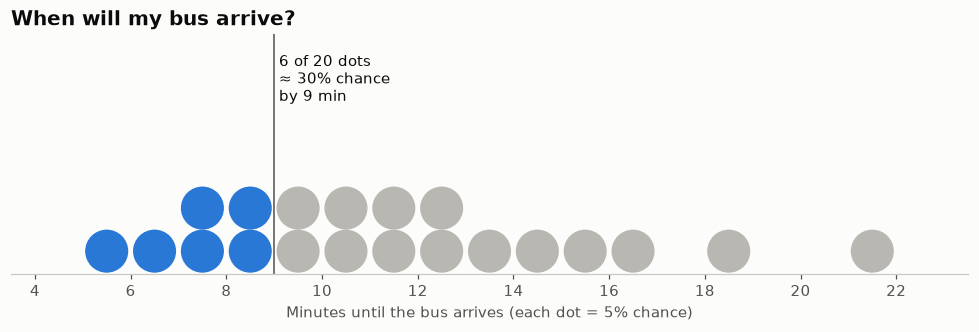

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
r = 0.45
counts = {}
for b in df["bin"]:
    k = counts.get(b, 0)
    counts[b] = k + 1
    color = PALETTE[0] if b < threshold else "#b8b7b1"
    ax.add_patch(Circle((b + 0.5, r + 2 * r * k + 0.02), r, color=color, linewidth=0))
n_before = int((df["bin"] < threshold).sum())
ax.axvline(threshold, color="#52514e", lw=1)
ax.text(threshold + 0.1, 4.6, f"{n_before} of {n_dots} dots\n≈ {n_before / n_dots:.0%} chance\nby {threshold} min",
        fontsize=9.5, color="#0b0b0b", va="top")
ax.set_xlim(df["bin"].min() - 1.5, df["bin"].max() + 2.5)
ax.set_ylim(0, 5)
ax.set_aspect("equal")
ax.set_yticks([])
ax.spines["left"].set_visible(False)
ax.grid(False)
ax.set_xticks(range(df["bin"].min() - 1, df["bin"].max() + 3, 2))
ax.set_xlabel("Minutes until the bus arrives (each dot = 5% chance)")
ax.set_title("When will my bus arrive?")
fig.tight_layout()
plt.show()

## How to read it

Each dot is a 1-in-20 (5%) chance, stacked in the one-minute interval it falls in. Six blue dots fall before the 9-minute line, so there is about a 30% chance the bus comes within 9 minutes. If you need 9 minutes to finish your coffee, you will catch it about seven times in ten.

## Reference

This method comes from the research literature:

- Kay, M., Kola, T., Hullman, J. R. & Munson, S. A. (2016). When (ish) is my bus? User-centered visualizations of uncertainty in everyday, mobile predictive systems. Proceedings of the ACM CHI Conference on Human Factors in Computing Systems (CHI 2016). <https://idl.uw.edu/papers/when-ish-is-my-bus>
- Fernandes, M., Walls, L., Munson, S., Hullman, J. & Kay, M. (2018). Uncertainty displays using quantile dotplots or CDFs improve transit decision-making. Proceedings of the ACM CHI Conference on Human Factors in Computing Systems (CHI 2018). <https://doi.org/10.1145/3173574.3173718>

---
Standalone script: [`quantile_dotplot.py`](quantile_dotplot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)